# Problem 1 — K-means trên Rice

**Câu hỏi:** scaling và $K$ thay đổi cụm ra sao? `random` so với `k-means++` ổn định thế nào? Một bước gán/cập nhật centroid có làm inertia tăng không?

**Quy tắc chọn trước khi xem kết quả:** silhouette cao nhất; trong khoảng 0.01 điểm từ cao nhất, chỉ nhận cụm tối thiểu 1% số hàng, sau đó ưu tiên $K$ nhỏ hơn và Davies–Bouldin thấp hơn. Nhãn giống lúa không tham gia. Các nhận xét động dưới đây tính từ output của chính lần chạy hiện tại.

## Dữ liệu và thiết kế thực nghiệm

[Rice Cammeo/Osmancik (UCI)](https://archive.ics.uci.edu/dataset/545/rice+cammeo+and+osmancik), 3.810 hàng, 7 đặc trưng số; DOI [10.24432/C5MW4Z](https://doi.org/10.24432/C5MW4Z), CC BY 4.0. `Class` không tham gia phân cụm/chọn mô hình. Vì đây là bài toán không giám sát trên toàn bộ dữ liệu, scaler được fit trên cùng 3.810 quan sát; không chia train/test theo nhãn. Silhouette dùng cùng 1.000 index ngẫu nhiên cố định cho mọi cấu hình nhằm hạn chế chi phí khoảng cách; các metric khác dùng toàn bộ dữ liệu. Inertia chỉ so sánh trong cùng một không gian raw hoặc scaled.

In [1]:
from __future__ import annotations
from hashlib import sha256
from pathlib import Path
from time import perf_counter
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display, Markdown
from scipy.io import arff
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler

SEED = 42
HASH = '1af97883100c89de2ea2972f7a28d428f4f1c14711a61defc0b0569e9eb65665'
NAMES = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']
KS = range(2, 11)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True})
print('Versions:', np.__version__, pd.__version__, scipy.__version__, sklearn.__version__)

Versions: 2.4.6 3.0.3 1.17.1 1.8.0


Data: data\Rice_Cammeo_Osmancik.arff shape: (3810, 7) missing: 0 duplicates: 0 SHA-256: 1af97883100c89de2ea2972f7a28d428f4f1c14711a61defc0b0569e9eb65665


,dtype
Area,float64
Perimeter,float64
Major_Axis_Length,float64
Minor_Axis_Length,float64
Eccentricity,float64
Convex_Area,float64
Extent,float64


,min,50%,mean,std,max
Area,7551.000,12421.500,12667.728,1732.368,18913.000
Perimeter,359.100,448.852,454.239,35.597,548.446
Major_Axis_Length,145.264,185.810,188.776,17.449,239.010
Minor_Axis_Length,59.532,86.435,86.314,5.730,107.542
Eccentricity,0.777,0.889,0.887,0.021,0.948
Convex_Area,7723.000,12706.500,12952.497,1776.972,19099.000
Extent,0.497,0.645,0.662,0.077,0.861


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
Area,1.00,0.97,0.90,0.79,0.35,1.00,-0.06
Perimeter,0.97,1.00,0.97,0.63,0.54,0.97,-0.13
Major_Axis_Length,0.90,0.97,1.00,0.45,0.71,0.90,-0.14
Minor_Axis_Length,0.79,0.63,0.45,1.00,-0.29,0.79,0.06
Eccentricity,0.35,0.54,0.71,-0.29,1.00,0.35,-0.20
Convex_Area,1.00,0.97,0.90,0.79,0.35,1.00,-0.07
Extent,-0.06,-0.13,-0.14,0.06,-0.20,-0.07,1.00


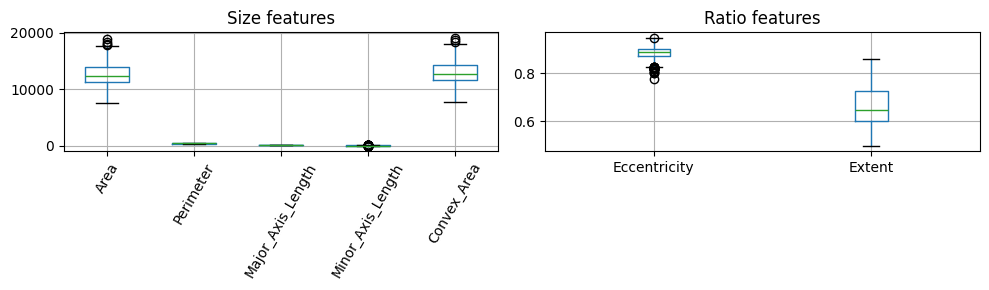

In [2]:
def data_path() -> Path:
    for path in [Path('data/Rice_Cammeo_Osmancik.arff'), Path('unsupervised-learning/data/Rice_Cammeo_Osmancik.arff')]:
        if path.is_file():
            return path
    raise FileNotFoundError('Rice ARFF not found; see README.md')

path = data_path()
assert sha256(path.read_bytes()).hexdigest() == HASH, 'Data checksum mismatch'
records, _ = arff.loadarff(path)
frame = pd.DataFrame(records)
y_true = frame['Class'].str.decode('ascii').to_numpy()
features = frame[NAMES].astype(float)
assert features.shape == (3810, 7) and features.index.is_unique
assert np.isfinite(features.to_numpy()).all()
print('Data:', path, 'shape:', features.shape, 'missing:', features.isna().sum().sum(),
      'duplicates:', features.duplicated().sum(), 'SHA-256:', HASH)
display(features.dtypes.rename('dtype').to_frame())
display(features.describe().T[['min', '50%', 'mean', 'std', 'max']].round(3))
display(features.corr().round(2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
features[['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length', 'Convex_Area']].boxplot(ax=ax[0], rot=60)
features[['Eccentricity', 'Extent']].boxplot(ax=ax[1])
ax[0].set_title('Size features'); ax[1].set_title('Ratio features')
plt.tight_layout(); plt.show()

**Cách đọc output dữ liệu:** `min`/`max` cho biết miền giá trị, `50%` là median, còn `std` đo mức phân tán quanh mean. `Area` và `Convex_Area` gần như tương quan hoàn hảo ($r\approx1$); `Perimeter` cũng tương quan mạnh với hai biến này. Vì vậy khoảng cách raw không chỉ ưu tiên nhóm đặc trưng kích thước do trị số lớn, mà còn có thể **đếm lặp** cùng tín hiệu kích thước qua nhiều chiều tương quan. `Eccentricity` và `Extent` nằm trên thang tỷ lệ nhỏ hơn nên đóng góp rất ít vào Euclidean raw.

Boxplot cho thấy miền số của hai nhóm đặc trưng khác nhau rõ rệt, nhưng điểm nằm ngoài whisker chưa mặc nhiên là lỗi: đây có thể là hạt thật có hình thái cực trị. Vì thế notebook giữ nguyên toàn bộ hàng, so sánh raw với chuẩn hóa, rồi kiểm tra độ nhạy outlier riêng. Không có missing/infinite/duplicate giúp loại trừ ba nguyên nhân kỹ thuật thường làm sai khoảng cách, nhưng không chứng minh mọi phép đo đều sạch nhiễu.

In [3]:
X_raw = features.to_numpy(copy=True)
X_scaled = StandardScaler().fit_transform(X_raw)
matrices = {'raw': X_raw, 'scaled': X_scaled}
sample_idx = np.sort(np.random.default_rng(SEED).choice(len(X_raw), 1000, replace=False))
assert len(np.unique(sample_idx)) == 1000

def sizes(labels: np.ndarray) -> str:
    return ', '.join(map(str, np.bincount(labels)))

def quality(X: np.ndarray, labels: np.ndarray) -> dict[str, float]:
    if len(np.unique(labels[sample_idx])) < 2:
        raise ValueError('Sample has fewer than two clusters')
    return {'silhouette': silhouette_score(X[sample_idx], labels[sample_idx]),
            'ch': calinski_harabasz_score(X, labels),
            'db': davies_bouldin_score(X, labels)}

print('Silhouette sample:', len(sample_idx), 'seed:', SEED)

Silhouette sample: 1000 seed: 42


## 1. Scaling và số cụm

K-means tối thiểu hóa $J=\sum_i\|x_i-\mu_{z_i}\|^2$. Inertia luôn giảm/giữ khi tăng $K$, nên đường elbow chỉ tìm điểm mà lợi ích biên bắt đầu giảm, không tự chứng minh số cụm đúng. Silhouette của điểm $i$ là $(b_i-a_i)/\max(a_i,b_i)$: gần 1 nghĩa là điểm gần cụm mình hơn cụm lân cận, gần 0 là nằm sát ranh giới, âm là có thể bị gán chưa hợp lý. Davies–Bouldin (DB) càng thấp càng tốt vì so độ phân tán trong cụm với khoảng cách giữa cụm; Calinski–Harabasz (CH) càng cao càng tốt nhưng thường thiên về nhiều cụm hơn. Quét $K=2..10$, `n_init=20`, seed 42 và đọc đồng thời các chỉ số.

D:\miniconda3\envs\ai-algorithms\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\miniconda3\envs\ai-algorithms\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\miniconda3\envs\ai-algorithms\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\miniconda3\envs\ai-algorithms\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^

,scale,k,inertia,silhouette,ch,db,sizes,min_size,runtime_ms
0,raw,2,7.104203e+09,0.596,8769.568,0.527,"2327, 1483",1483,1239.359
1,raw,3,3.730169e+09,0.542,10070.536,0.556,"1337, 1433, 1040",1040,196.144
2,raw,4,2.356942e+09,0.514,11361.784,0.578,"913, 921, 1350, 626",626,291.911
3,raw,5,1.609930e+09,0.516,12913.306,0.575,"777, 1079, 922, 642, 390",390,354.389
4,raw,6,1.163432e+09,0.511,14583.510,0.559,"927, 618, 905, 453, 652, 255",255,365.481
5,raw,7,8.666124e+08,0.520,16528.097,0.540,"579, 626, 824, 247, 743, 578, 213",213,383.664
6,raw,8,6.768378e+08,0.522,18286.634,0.534,"747, 501, 207, 704, 144, 402, 592, 513",144,600.425
7,raw,9,5.439755e+08,0.525,20020.634,0.531,"623, 450, 452, 167, 514, 539, 119, 296, 650",119,522.587
8,raw,10,4.547881e+08,0.489,21362.848,0.538,"437, 583, 441, 295, 330, 564, 414, 118, 129, 499",118,398.003
9,scaled,2,1.392879e+04,0.396,3483.328,0.951,"1576, 2234",1576,110.690


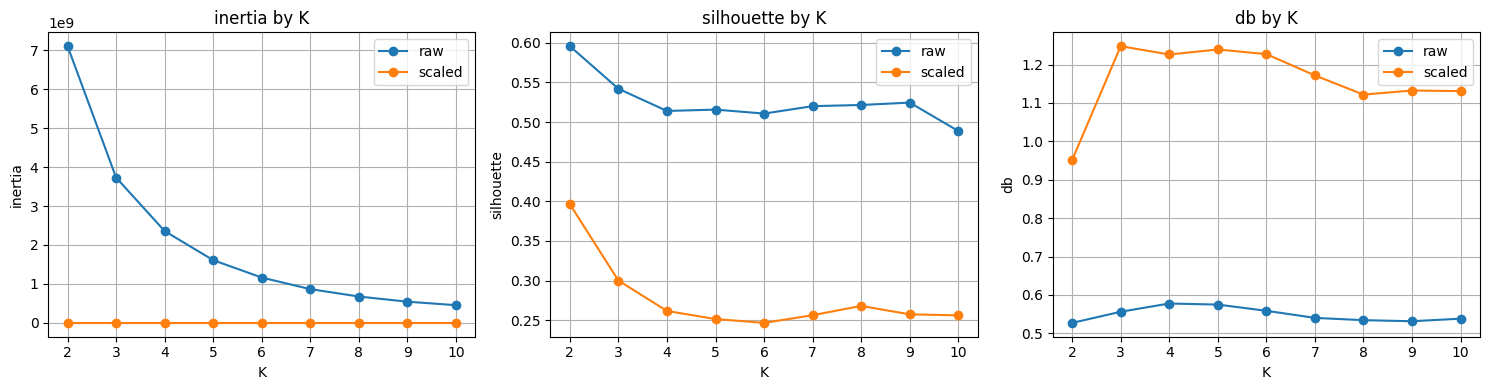

**Đọc bảng và ba đường cong:** ở K=2, raw đạt silhouette 0.596, cao hơn scaled (0.396) 0.199 điểm. Khi tăng raw từ K=2 lên K=3, inertia giảm 47.5% nhưng silhouette lại giảm từ 0.596 xuống 0.542. Nghĩa là tâm cụm mô tả dữ liệu sát hơn theo SSE, nhưng các nhóm mới kém tách biệt hơn theo khoảng cách tương đối. Đây là ví dụ vì sao không được chọn K chỉ bằng inertia. Raw thắng về silhouette chủ yếu cho thấy cấu trúc kích thước chi phối tạo hai khối rõ trong metric Euclidean; nó chưa chứng minh các biến tỷ lệ không quan trọng về mặt miền bài toán.

In [4]:
rows = []
models = {}
for scale, X in matrices.items():
    for k in KS:
        model = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED)
        start = perf_counter()
        labels = model.fit_predict(X)
        runtime = (perf_counter() - start) * 1000
        rows.append({'scale': scale, 'k': k, 'inertia': model.inertia_,
                     **quality(X, labels), 'sizes': sizes(labels),
                     'min_size': np.bincount(labels).min(), 'runtime_ms': runtime})
        models[(scale, k)] = model
grid = pd.DataFrame(rows)
display(grid.round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for scale, part in grid.groupby('scale'):
    for axis, metric in zip(axes, ['inertia', 'silhouette', 'db']):
        axis.plot(part.k, part[metric], marker='o', label=scale)
        axis.set(xlabel='K', ylabel=metric, title=f'{metric} by K'); axis.legend()
plt.tight_layout(); plt.show()
raw_k2 = grid[(grid.scale == 'raw') & (grid.k == 2)].iloc[0]
raw_k3 = grid[(grid.scale == 'raw') & (grid.k == 3)].iloc[0]
scaled_k2 = grid[(grid.scale == 'scaled') & (grid.k == 2)].iloc[0]
inertia_drop = 100 * (raw_k2.inertia - raw_k3.inertia) / raw_k2.inertia
display(Markdown(
    f'**Đọc bảng và ba đường cong:** ở K=2, raw đạt silhouette {raw_k2.silhouette:.3f}, '
    f'cao hơn scaled ({scaled_k2.silhouette:.3f}) {raw_k2.silhouette-scaled_k2.silhouette:.3f} điểm. '
    f'Khi tăng raw từ K=2 lên K=3, inertia giảm {inertia_drop:.1f}% nhưng silhouette lại giảm '
    f'từ {raw_k2.silhouette:.3f} xuống {raw_k3.silhouette:.3f}. Nghĩa là tâm cụm mô tả dữ liệu sát hơn '
    'theo SSE, nhưng các nhóm mới kém tách biệt hơn theo khoảng cách tương đối. Đây là ví dụ vì sao không '
    'được chọn K chỉ bằng inertia. Raw thắng về silhouette chủ yếu cho thấy cấu trúc kích thước chi phối '
    'tạo hai khối rõ trong metric Euclidean; nó chưa chứng minh các biến tỷ lệ không quan trọng về mặt miền bài toán.'))

,scale,k,inertia,silhouette,ch,db,sizes,min_size,runtime_ms
0,raw,2,7.104203e+09,0.596,8769.568,0.527,"2327, 1483",1483,1239.359


**Vì sao cấu hình này được chọn:** `raw`, K=2 có silhouette 0.596, DB=0.527 và cụm nhỏ nhất 1483 mẫu. Tỷ lệ cụm nhỏ/lớn là 0.637, nên kết quả không phải trường hợp một cụm chính cộng một nhóm vài điểm cực trị. Tie band 0.01 chỉ chứa cấu hình ở bảng shortlist; quy tắc ưu tiên K nhỏ giúp tránh chia nhỏ khi mức tách biệt không tăng đáng kể. Inertia chỉ có nghĩa so sánh trong cùng scale.

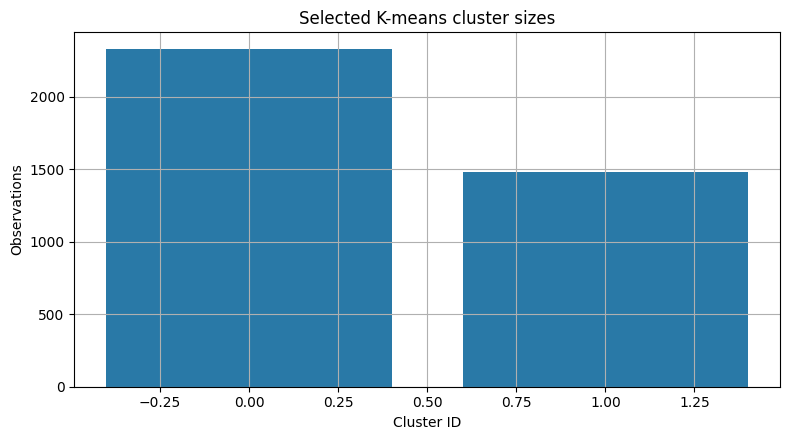

In [5]:
eligible = grid[grid.min_size >= int(np.ceil(.01 * len(X_raw)))]
assert not eligible.empty
shortlist = eligible[eligible.silhouette >= eligible.silhouette.max() - .01]
selected = shortlist.sort_values(['k', 'db', 'runtime_ms']).iloc[0]
selected_scale, selected_k = str(selected['scale']), int(selected['k'])
X_selected = matrices[selected_scale]
final_model = models[(selected_scale, selected_k)]
display(shortlist.round(3))
cluster_counts = np.bincount(final_model.labels_)
balance_ratio = cluster_counts.min() / cluster_counts.max()
display(Markdown(
    f'**Vì sao cấu hình này được chọn:** `{selected_scale}`, K={selected_k} có silhouette '
    f'{selected.silhouette:.3f}, DB={selected.db:.3f} và cụm nhỏ nhất {int(selected.min_size)} mẫu. '
    f'Tỷ lệ cụm nhỏ/lớn là {balance_ratio:.3f}, nên kết quả không phải trường hợp một cụm chính cộng '
    'một nhóm vài điểm cực trị. Tie band 0.01 chỉ chứa cấu hình ở bảng shortlist; quy tắc ưu tiên K nhỏ '
    'giúp tránh chia nhỏ khi mức tách biệt không tăng đáng kể. Inertia chỉ có nghĩa so sánh trong cùng scale.'))
plt.bar(np.arange(selected_k), np.bincount(final_model.labels_), color='#2979a7')
plt.title('Selected K-means cluster sizes'); plt.xlabel('Cluster ID'); plt.ylabel('Observations')
plt.tight_layout(); plt.show()

## 2. Khởi tạo và ổn định

Giữ $K$/scale đã chọn. Với cùng 20 seed, `n_init=1` phơi bày ảnh hưởng của điểm khởi tạo; ARI giữa các run đo độ nhất quán phân hoạch, không dùng nhãn thật.

In [6]:
runs = []
partitions = {}
for init in ['random', 'k-means++']:
    partitions[init] = []
    for seed in range(SEED, SEED + 20):
        model = KMeans(n_clusters=selected_k, init=init, n_init=1, random_state=seed)
        start = perf_counter()
        labels = model.fit_predict(X_selected)
        runtime = (perf_counter() - start) * 1000
        runs.append({'init': init, 'seed': seed, 'inertia': model.inertia_,
                     'silhouette': quality(X_selected, labels)['silhouette'], 'runtime_ms': runtime})
        partitions[init].append(labels)
run_table = pd.DataFrame(runs)
summary = []
for init, part in run_table.groupby('init', sort=False):
    pair_ari = [adjusted_rand_score(a, b) for a, b in combinations(partitions[init], 2)]
    summary.append({'init': init, 'runs': len(part), 'inertia_mean': part.inertia.mean(),
                    'inertia_std': part.inertia.std(), 'inertia_min': part.inertia.min(),
                    'inertia_max': part.inertia.max(), 'sil_mean': part.silhouette.mean(),
                    'sil_std': part.silhouette.std(), 'sil_min': part.silhouette.min(),
                    'sil_max': part.silhouette.max(), 'runtime_mean_ms': part.runtime_ms.mean(),
                    'runtime_std_ms': part.runtime_ms.std(),
                    'runtime_min_ms': part.runtime_ms.min(),
                    'runtime_max_ms': part.runtime_ms.max(),
                    'pairwise_ari': np.mean(pair_ari)})
init_summary = pd.DataFrame(summary)
display(init_summary.round(4))
relative_inertia_gap = 100 * (summary[0]['inertia_mean'] - summary[1]['inertia_mean']) / summary[0]['inertia_mean']
display(Markdown(
    f'**Đọc bảng ổn định:** inertia trung bình của `random` và `k-means++` lần lượt là '
    f'{summary[0]["inertia_mean"]:.2f} và {summary[1]["inertia_mean"]:.2f}; lợi thế tương đối của '
    f'`k-means++` chỉ khoảng {relative_inertia_gap:.6f}%. Hai silhouette mean cùng làm tròn thành '
    f'{summary[0]["sil_mean"]:.4f}. Pairwise ARI {summary[0]["pairwise_ari"]:.3f} và '
    f'{summary[1]["pairwise_ari"]:.3f} nghĩa là hai run gần như gán cùng các cặp điểm vào cùng cụm, '
    'dù ID 0/1 có thể hoán đổi. ARI chưa đúng 1 cho thấy một số điểm sát ranh giới vẫn đổi cụm. '
    f'Runtime dao động từ {summary[0]["runtime_min_ms"]:.1f}–{summary[0]["runtime_max_ms"]:.1f} ms '
    f'với random và {summary[1]["runtime_min_ms"]:.1f}–{summary[1]["runtime_max_ms"]:.1f} ms với '
    '`k-means++`; vì nhiễu hệ thống lớn, không dùng chênh lệch thời gian nhỏ để kết luận init nào nhanh hơn. '
    'Kết quả cho thấy bài toán K=2 trên Rice có basin nghiệm rất mạnh; với K lớn hoặc cụm chồng lấn, '
    'khác biệt initialization có thể rõ hơn.'))

,init,runs,inertia_mean,inertia_std,inertia_min,inertia_max,sil_mean,sil_std,sil_min,sil_max,runtime_mean_ms,runtime_std_ms,runtime_min_ms,runtime_max_ms,pairwise_ari
0,random,20,7.104237e+09,73672.6505,7.104203e+09,7.104407e+09,0.5958,0.0,0.5958,0.5958,9.8008,0.9954,8.1059,12.0910,0.9989
1,k-means++,20,7.104228e+09,61958.4078,7.104203e+09,7.104407e+09,0.5958,0.0,0.5958,0.5958,10.1016,1.4042,7.4866,12.9309,0.9990


**Đọc bảng ổn định:** inertia trung bình của `random` và `k-means++` lần lượt là 7104237475.53 và 7104228106.24; lợi thế tương đối của `k-means++` chỉ khoảng 0.000132%. Hai silhouette mean cùng làm tròn thành 0.5958. Pairwise ARI 0.999 và 0.999 nghĩa là hai run gần như gán cùng các cặp điểm vào cùng cụm, dù ID 0/1 có thể hoán đổi. ARI chưa đúng 1 cho thấy một số điểm sát ranh giới vẫn đổi cụm. Runtime dao động từ 8.1–12.1 ms với random và 7.5–12.9 ms với `k-means++`; vì nhiễu hệ thống lớn, không dùng chênh lệch thời gian nhỏ để kết luận init nào nhanh hơn. Kết quả cho thấy bài toán K=2 trên Rice có basin nghiệm rất mạnh; với K lớn hoặc cụm chồng lấn, khác biệt initialization có thể rõ hơn.

## 3. Một bước NumPy trên hai đặc trưng thật

Chọn 12 hàng thật, `Major_Axis_Length`/`Eccentricity`, centroid ban đầu từ hai hàng trong mẫu. `argmin` xử lý hòa khoảng cách bằng chỉ số centroid nhỏ hơn; cụm rỗng là lỗi phải xử lý minh bạch.

In [7]:
demo_idx = np.array([0, 1, 2, 3, 4, 5, 1800, 1801, 1802, 1803, 1804, 1805])
demo = features.loc[demo_idx, ['Major_Axis_Length', 'Eccentricity']].to_numpy()
demo_z = StandardScaler().fit_transform(demo)
initial = demo_z[[0, 6]].copy()
before = ((demo_z[:, None, :] - initial[None, :, :]) ** 2).sum(axis=2)
assignment = np.argmin(before, axis=1)
old_inertia = before[np.arange(len(demo_z)), assignment].sum()
if len(np.unique(assignment)) < len(initial):
    raise ValueError('Empty demo cluster')
updated = np.vstack([demo_z[assignment == c].mean(axis=0) for c in range(len(initial))])
update_inertia = ((demo_z - updated[assignment]) ** 2).sum()
after = ((demo_z[:, None, :] - updated[None, :, :]) ** 2).sum(axis=2)
reassigned = np.argmin(after, axis=1)
new_inertia = after[np.arange(len(demo_z)), reassigned].sum()
assert update_inertia <= old_inertia + 1e-10
assert new_inertia <= update_inertia + 1e-10
display(pd.DataFrame(demo, columns=['Major_Axis_Length', 'Eccentricity'], index=demo_idx).assign(cluster=assignment, next_cluster=reassigned))
display(pd.DataFrame(initial, columns=['Major_Axis_Length_z', 'Eccentricity_z']).assign(stage='initial'))
display(pd.DataFrame(updated, columns=['Major_Axis_Length_z', 'Eccentricity_z']).assign(stage='updated'))
print(f'Inertia assignment={old_inertia:.6f}; update={update_inertia:.6f}; reassignment={new_inertia:.6f}')
update_reduction = 100 * (old_inertia - update_inertia) / old_inertia
reassign_reduction = 100 * (update_inertia - new_inertia) / update_inertia
moved = int(np.sum(assignment != reassigned))
display(Markdown(
    f'**Giải thích số liệu iteration:** cập nhật centroid làm inertia giảm {update_reduction:.1f}% '
    f'({old_inertia:.3f} → {update_inertia:.3f}) trong khi giữ assignment cũ. Khi gán lại với tâm mới, '
    f'{moved}/{len(demo_z)} điểm đổi cụm và inertia giảm thêm {reassign_reduction:.1f}% xuống '
    f'{new_inertia:.3f}. Mức giảm đầu lớn cho thấy hai centroid ban đầu chưa nằm gần trung bình của nhóm; '
    'mức giảm sau nhỏ hơn cho thấy phân hoạch đã tiến gần trạng thái tự nhất quán. Ví dụ chỉ dùng hai '
    'đặc trưng và 12 điểm để minh họa phép toán, không phải mô hình cuối trên bảy chiều.'))

,Major_Axis_Length,Eccentricity,cluster,next_cluster
0,229.749878,0.928882,0,0
1,206.020065,0.895405,1,0
2,214.106781,0.912118,0,0
3,193.337387,0.891861,1,1
4,211.743378,0.906691,0,0
5,200.053055,0.901328,1,0
1800,186.587723,0.900983,1,1
1801,168.533478,0.861313,1,1
1802,176.343948,0.855574,1,1
1803,177.986343,0.855271,1,1


,Major_Axis_Length_z,Eccentricity_z,stage
0,2.004702,1.778418,initial
1,-0.383912,0.540311,initial


,Major_Axis_Length_z,Eccentricity_z,stage
0,1.383974,1.202171,updated
1,-0.461325,-0.400724,updated


Inertia assignment=20.733545; update=10.557605; reassignment=9.926862


**Giải thích số liệu iteration:** cập nhật centroid làm inertia giảm 49.1% (20.734 → 10.558) trong khi giữ assignment cũ. Khi gán lại với tâm mới, 2/12 điểm đổi cụm và inertia giảm thêm 6.0% xuống 9.927. Mức giảm đầu lớn cho thấy hai centroid ban đầu chưa nằm gần trung bình của nhóm; mức giảm sau nhỏ hơn cho thấy phân hoạch đã tiến gần trạng thái tự nhất quán. Ví dụ chỉ dùng hai đặc trưng và 12 điểm để minh họa phép toán, không phải mô hình cuối trên bảy chiều.

Với centroid cố định, gán về tâm gần nhất tối thiểu hóa từng số hạng của $J$. Với assignment cố định, mean tối thiểu hóa tổng bình phương sai số của cụm. Vì vậy hai bước không tăng objective, nhưng nghiệm phụ thuộc khởi tạo nên hội tụ không bảo đảm cực tiểu toàn cục.

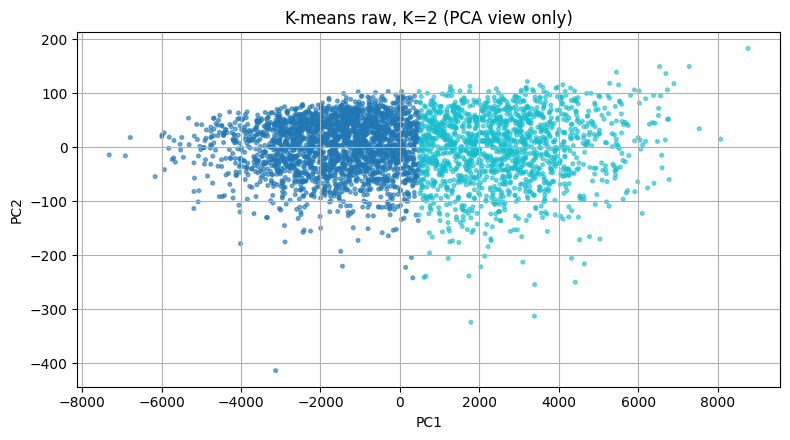

Final cluster sizes: 2327, 1483


**Đọc hình PCA:** hai trục đầu giữ 99.9977% phương sai số học của không gian raw. Tỷ lệ gần 100% chủ yếu vì các biến Area/Convex Area có phương sai theo đơn vị rất lớn và gần đồng tuyến; nó không có nghĩa hai PC giữ 100% mọi ý nghĩa hình thái. Nếu hai màu chồng lên nhau trên hình, điều đó có thể do mất thông tin khi chiếu xuống 2D; ngược lại, tách rõ trên hình chỉ là bằng chứng trực quan, không thay silhouette trên không gian bảy chiều. Kích thước cụm cho biết K-means đang tách hai nhóm hình thái có quy mô đáng kể chứ không cô lập một vài outlier.

In [8]:
pca_model = PCA(n_components=2, random_state=SEED)
projection = pca_model.fit_transform(X_selected)
plt.scatter(projection[:, 0], projection[:, 1], c=final_model.labels_, s=7, cmap='tab10', alpha=.6)
plt.title(f'K-means {selected_scale}, K={selected_k} (PCA view only)')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.tight_layout(); plt.show()
print('Final cluster sizes:', sizes(final_model.labels_))
display(Markdown(
    f'**Đọc hình PCA:** hai trục đầu giữ {100*pca_model.explained_variance_ratio_.sum():.4f}% phương sai '
    'số học của không gian raw. Tỷ lệ gần 100% chủ yếu vì các biến Area/Convex Area có phương sai theo '
    'đơn vị rất lớn và gần đồng tuyến; nó không có nghĩa hai PC giữ 100% mọi ý nghĩa hình thái. Nếu hai '
    'màu chồng lên nhau trên hình, điều đó có thể do mất thông tin '
    'khi chiếu xuống 2D; ngược lại, tách rõ trên hình chỉ là bằng chứng trực quan, không thay silhouette '
    'trên không gian bảy chiều. Kích thước cụm cho biết K-means đang tách hai nhóm hình thái có quy mô '
    'đáng kể chứ không cô lập một vài outlier.'))